### LSE Data Analytics Online Career Accelerator 

# DA301:  Advanced Analytics for Organisational Impact

## Assignment template

### Scenario
You are a data analyst working for Turtle Games, a game manufacturer and retailer. They manufacture and sell their own products, along with sourcing and selling products manufactured by other companies. Their product range includes books, board games, video games and toys. They have a global customer base and have a business objective of improving overall sales performance by utilising customer trends. In particular, Turtle Games wants to understand: 
- how customers accumulate loyalty points (Week 1)
- exploring the structure using decision trees (Week 2)
- exploring clusters in customer behaviour (Week 3)
- can social data (e.g. customer reviews) be used in marketing campaigns (Week 4)
- loading, transforming and visualising data in R (Week 5)
- statistical analysis and modelling in R (Week 6)

# Week 1 assignment: Linear regression using Python
The marketing department of Turtle Games prefers Python for data analysis. As you are fluent in Python, they asked you to assist with data analysis of social media data. The marketing department wants to better understand how users accumulate loyalty points. Therefore, you need to investigate the possible relationships between the loyalty points, age, remuneration, and spending scores. Note that you will use this data set in future modules as well and it is, therefore, strongly encouraged to first clean the data as per provided guidelines and then save a copy of the clean data for future use.

## Instructions
1. Load and explore the data.
    1. Create a new DataFrame (e.g. reviews).
    2. Sense-check the DataFrame.
    3. Determine if there are any missing values in the DataFrame.
    4. Create a summary of the descriptive statistics.
2. Remove redundant columns (`language` and `platform`).
3. Change column headings to names that are easier to reference (e.g. `renumeration` and `spending_score`).
4. Save a copy of the clean DataFrame as a CSV file. Import the file to sense-check.
5. Use linear regression and goodness of fit metrics to evaluate possible linear relationships between loyalty points and age/renumeration/spending scores to determine whether these can be used to predict the loyalty points.
    1. Specify the independent and dependent variables.
    2. Create the OLS model.
    3. Extract the estimated parameters, standard errors, and predicted values.
    4. Generate the regression table based on the X coefficient and constant values.
    5. Plot the linear regression and add a regression line.
6. Include your insights and observations.

## 1. Load and explore the data

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm 
from statsmodels.formula.api import ols

In [2]:
# Load the CSV file(s) as reviews.
reviews = pd.read_csv('turtle_reviews.csv')

# View the DataFrame.
reviews.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap


In [3]:
# Any missing values?
reviews.isna().sum()

gender                    0
age                       0
remuneration (k£)         0
spending_score (1-100)    0
loyalty_points            0
education                 0
language                  0
platform                  0
product                   0
review                    0
summary                   0
dtype: int64

In [4]:
# Explore the data.
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   str    
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   str    
 6   language                2000 non-null   str    
 7   platform                2000 non-null   str    
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   str    
 10  summary                 2000 non-null   str    
dtypes: float64(1), int64(4), str(6)
memory usage: 172.0 KB


In [5]:
reviews.dtypes

gender                        str
age                         int64
remuneration (k£)         float64
spending_score (1-100)      int64
loyalty_points              int64
education                     str
language                      str
platform                      str
product                     int64
review                        str
summary                       str
dtype: object

In [6]:
# Basic descriptive statistics.
reviews.describe()

,age,remuneration (k£),spending_score (1-100),loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


## 2. Drop columns

In [7]:
# Drop unnecessary columns.
reviews = reviews.drop(columns=['language', 'platform'])

# View column names.
reviews.columns

Index(['gender', 'age', 'remuneration (k£)', 'spending_score (1-100)',
       'loyalty_points', 'education', 'product', 'review', 'summary'],
      dtype='str')

## 3. Rename columns

In [8]:
# Rename the column headers.
reviews = reviews.rename(columns={'remuneration (k£)': 'renumeration',
                                   'spending_score (1-100)': 'spending_score'})

# View column names.
reviews.columns

Index(['gender', 'age', 'renumeration', 'spending_score', 'loyalty_points',
       'education', 'product', 'review', 'summary'],
      dtype='str')

## 4. Save the DataFrame as a CSV file

In [9]:
# Create a CSV file as output.
reviews.to_csv('reviews_clean.csv', index=False)

In [10]:
# Import new CSV file with Pandas.
reviews2 = pd.read_csv('reviews_clean.csv')

# View DataFrame.
reviews2.info()
reviews2.head()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          2000 non-null   str    
 1   age             2000 non-null   int64  
 2   renumeration    2000 non-null   float64
 3   spending_score  2000 non-null   int64  
 4   loyalty_points  2000 non-null   int64  
 5   education       2000 non-null   str    
 6   product         2000 non-null   int64  
 7   review          2000 non-null   str    
 8   summary         2000 non-null   str    
dtypes: float64(1), int64(4), str(4)
memory usage: 140.8 KB


,gender,age,renumeration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


## 5. Linear regression

### 5a) spending vs loyalty

In [11]:
# Define independent variable.
X = reviews2['spending_score']

# Define dependent variable.
Y = reviews2['loyalty_points']

# Create model and print summary of metrics.
f1 = 'loyalty_points ~ spending_score'
model1 = ols(f1, data=reviews2).fit()
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         loyalty_points   R-squared:                       0.452
Model:                            OLS   Adj. R-squared:                  0.452
Method:                 Least Squares   F-statistic:                     1648.
Date:                Sun, 19 Jul 2026   Prob (F-statistic):          2.92e-263
Time:                        18:01:30   Log-Likelihood:                -16550.
No. Observations:                2000   AIC:                         3.310e+04
Df Residuals:                    1998   BIC:                         3.312e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -75.0527     45.931     -1.634      0.102    -165.129      15.024
spending_score    33.0617      0.814     40.595      0.000      31.464      34.659
==============================================================================
Omnibus:                      126.554   Durbin-Watson:                   1.191
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              260.528
Skew:                           0.422   Prob(JB):                     2.67e-57
Kurtosis:                       4.554   Cond. No.                         122.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [12]:
# Extract the estimated parameters.
print('Parameters:', model1.params)

# Extract the standard errors.
print('Standard errors:', model1.bse)

# Extract the predicted values.
print('Predicted values:', model1.predict())

Parameters: Intercept        -75.052663
spending_score    33.061693
dtype: float64
Standard errors: Intercept         45.930554
spending_score     0.814419
dtype: float64
Predicted values: [1214.35337415 2602.94449102  123.31749662 ... 2933.56142361  453.93442921
  189.44088314]


In [13]:
# Set the X coefficient and the constant to generate the regression table.
X1 = X
Y1 = model1.params.iloc[1] * X1 + model1.params.iloc[0]

# View the output.
print(Y1.head())

0    1214.353374
1    2602.944491
2     123.317497
3    2470.697718
4    1247.415067
Name: spending_score, dtype: float64


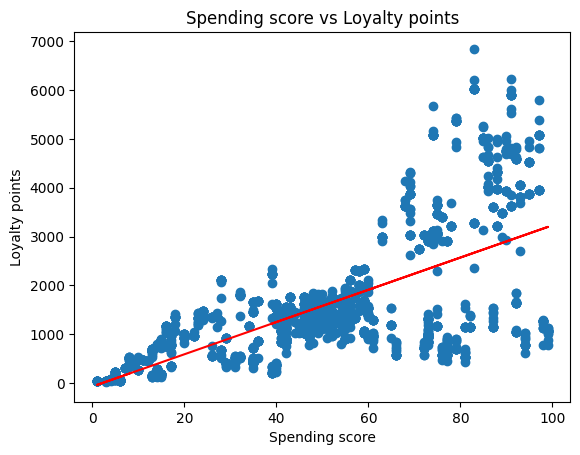

In [14]:
# Plot the graph with a regression line.
plt.scatter(X, Y)
plt.plot(X1, Y1, color='red')
plt.title('Spending score vs Loyalty points')
plt.xlabel('Spending score')
plt.ylabel('Loyalty points')
plt.show()

### 5b) renumeration vs loyalty

In [15]:
# Define independent variable.
X = reviews2['renumeration']

# Define dependent variable.
Y = reviews2['loyalty_points']

# Create model and print summary of metrics.
f2 = 'loyalty_points ~ renumeration'
model2 = ols(f2, data=reviews2).fit()
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         loyalty_points   R-squared:                       0.380
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     1222.
Date:                Sun, 19 Jul 2026   Prob (F-statistic):          2.43e-209
Time:                        18:01:30   Log-Likelihood:                -16674.
No. Observations:                2000   AIC:                         3.335e+04
Df Residuals:                    1998   BIC:                         3.336e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -65.6865     52.171     -1.259      0.208    -168.001      36.628
renumeration    34.1878      0.978     34.960      0.000      32.270      36.106
==============================================================================
Omnibus:                       21.285   Durbin-Watson:                   3.622
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               31.715
Skew:                           0.089   Prob(JB):                     1.30e-07
Kurtosis:                       3.590   Cond. No.                         123.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [16]:
# Extract the estimated parameters.
print('Parameters:', model2.params)

# Extract the standard errors.
print('Standard errors:', model2.bse)

# Extract the predicted values.
print('Predicted values:', model2.predict())

Parameters: Intercept      -65.686513
renumeration    34.187825
dtype: float64
Standard errors: Intercept       52.170717
renumeration     0.977925
dtype: float64
Predicted values: [ 354.82374068  354.82374068  382.85775758 ... 3102.15739671 3298.39551499
 3102.15739671]


In [17]:
# Set the the X coefficient and the constant to generate the regression table.
X2 = X
Y2 = model2.params.iloc[1] * X2 + model2.params.iloc[0]

# View the output.
print(Y2.head())

0    354.823741
1    354.823741
2    382.857758
3    382.857758
4    410.891774
Name: renumeration, dtype: float64


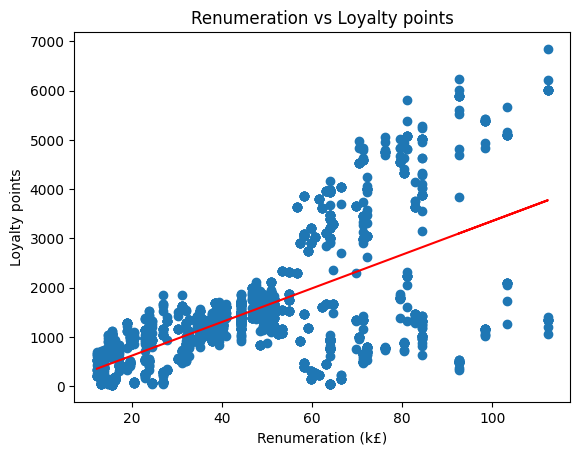

In [18]:
# Plot graph with regression line.
plt.scatter(X, Y)
plt.plot(X2, Y2, color='red')
plt.title('Renumeration vs Loyalty points')
plt.xlabel('Renumeration (k£)')
plt.ylabel('Loyalty points')
plt.show()

### 5c) age vs loyalty

In [19]:
# Define independent variable.
X = reviews2['age']

# Define dependent variable.
Y = reviews2['loyalty_points']

# Create model and print summary of metrics.
f3 = 'loyalty_points ~ age'
model3 = ols(f3, data=reviews2).fit()
model3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         loyalty_points   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     3.606
Date:                Sun, 19 Jul 2026   Prob (F-statistic):             0.0577
Time:                        18:01:30   Log-Likelihood:                -17150.
No. Observations:                2000   AIC:                         3.430e+04
Df Residuals:                    1998   BIC:                         3.431e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1736.5177     88.249     19.678      0.000    1563.449    1909.587
age           -4.0128      2.113     -1.899      0.058      -8.157       0.131
==============================================================================
Omnibus:                      481.477   Durbin-Watson:                   2.277
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              937.734
Skew:                           1.449   Prob(JB):                    2.36e-204
Kurtosis:                       4.688   Cond. No.                         129.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [20]:
# Extract the estimated parameters.
print('Parameters:', model3.params)

# Extract the standard errors.
print('Standard errors:', model3.bse)

# Extract the predicted values.
print('Predicted values:', model3.predict())

Parameters: Intercept    1736.517739
age            -4.012805
dtype: float64
Standard errors: Intercept    88.248731
age           2.113177
dtype: float64
Predicted values: [1664.2872467  1644.22322095 1648.2360261  ... 1600.0823643  1600.0823643
 1608.1079746 ]


In [21]:
# Set the X coefficient and the constant to generate the regression table.
X3 = X
Y3 = model3.params.iloc[1] * X3 + model3.params.iloc[0]

# View the output.
print(Y3.head())

0    1664.287247
1    1644.223221
2    1648.236026
3    1636.197611
4    1604.095169
Name: age, dtype: float64


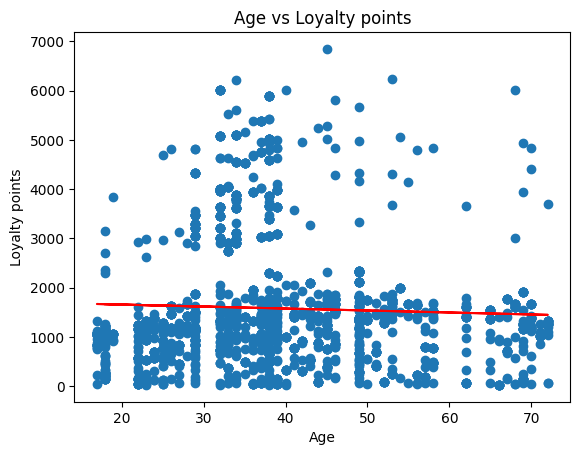

In [22]:
# Plot graph with regression line.
plt.scatter(X, Y)
plt.plot(X3, Y3, color='red')
plt.title('Age vs Loyalty points')
plt.xlabel('Age')
plt.ylabel('Loyalty points')
plt.show()

## 6. Observations and insights

***Your observations here...***

- Spending score vs loyalty points: R-squared ≈ 0.45, the strongest of the three single-variable models. There is a clear positive linear relationship: customers with higher spending scores tend to accumulate more loyalty points, and the relationship is statistically significant (p < 0.001).
- Renumeration vs loyalty points: R-squared ≈ 0.38, also a moderate positive and statistically significant relationship (p < 0.001). Customers who earn more tend to have more loyalty points, though the relationship is weaker than spending score.
- Age vs loyalty points: R-squared ≈ 0.002, essentially no linear relationship, and the coefficient is not statistically significant at the 5% level (p ≈ 0.058). Age alone is not a useful predictor of loyalty points.
- Overall: spending score and renumeration each show a moderate linear relationship with loyalty points and could contribute to a predictive model (for example, in a multiple regression), whereas age does not appear to be a useful linear predictor on its own. Since no single variable explains the majority of the variance, a combined/multiple regression model, or a non-linear approach, is likely to be needed to reliably predict loyalty points.

# Week 2 assignment: Exploring the structure using decision trees.

The team wants you to use decision trees to attempt to better understand the structure found in the data. You need to grow and prune a decision tree regressor and then visualise and interpret the output.
Make sure to comment on the potential usefulness in decision-making processes and your observations regarding the model.

## Instructions
1. Prepare the data for creating your decision tree. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame with the appropriate columns.
        1. Specify that loyalty points is the target variable (Y) and should be excluded from your input data.
        2. Specify X for the independent variables and y as the dependent variable. Therefore, df\[cols\] will be the independent variables and the column containing loyalty points the dependent variable.
        3. Explore the new DataFrame. 
2. Split the data set into a train and test sets for both X and y at a 70:30 ratio. As previously, random_state=42.
3. Create a decision tree regressor to explore the impact of other features on the loyalty points.
    1. Import the DecisionTreeRegressor class from the sklearn.tree library. 
    2. Create a variable (e.g. regressor) to store the DecisionTreeRegressor() class. (As previously, random_state=42.).
    3. Fit the regressor object to the data set with the fit() function.
    4. Remember to prune your tree using basic pruning strategies and compare the performance before and after applying the pruning strategy.
    5. Plot the final decision tree.
4. Fit a final model and interpret the output.
    1. Justify your selection of pruning strategy implemented and interpret the output.
    2. Evaluate the usefulness of the obtained result and interpret the tree and how it could be used to inform business decisions in the organisation.
5. Summarise (150–200 words) the most important business insights, anything you would like to explore further, and suggested future actions.
 
Back up your work to a safe location. This will allow you to revert to a previous state in the case of making a mistake in the code or deleting a section by mistake. (A simple way of doing this is to save or email a compressed version to yourself at frequent intervals.)


## 1. Load and prepare the data

In [2]:
# Import all the necessary packages
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, plot_tree
# Note: plot_confusion_matrix and the classification metrics in the original
# template are for classification tasks. Since loyalty_points is a continuous
# target, we use regression metrics instead (mean_squared_error, r2_score).
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import warnings
import matplotlib.pyplot as plt

# Settings for the notebook.
warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize'] = [15, 10]

In [7]:
# Create your new DataFrame.
df1 = pd.read_csv('turtle_reviews_clean.csv')
df1 = df1[['age', 'renumeration', 'spending_score', 'loyalty_points']]
df1.head()

,age,renumeration,spending_score,loyalty_points
0,18,12.30,39,210
1,23,12.30,81,524
2,22,13.12,6,40
3,25,13.12,77,562
4,33,13.94,40,366


In [8]:
# Specify Y.
y = df1['loyalty_points']

# Specify X.
X = df1.drop(columns=['loyalty_points'])

In [9]:
# Review X and Y.
print('X shape:', X.shape)
print(X.head())
print('\ny shape:', y.shape)
print(y.head())

X shape: (2000, 3)
   age  renumeration  spending_score
0   18         12.30              39
1   23         12.30              81
2   22         13.12               6
3   25         13.12              77
4   33         13.94              40

y shape: (2000,)
0    210
1    524
2     40
3    562
4    366
Name: loyalty_points, dtype: int64


## 2. Create train and test data sets.

In [10]:
# Split the data into test and train data.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print('Training set:', X_train.shape, y_train.shape)
print('Test set:', X_test.shape, y_test.shape)

Training set: (1400, 3) (1400,)
Test set: (600, 3) (600,)


## 3. Create Decision tree regressor

In [11]:
# Create your decision tree regressor.
regressor = DecisionTreeRegressor(random_state=42)
regressor.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [12]:
# Check how good the model's predictions are.
y_pred = regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Full tree - MSE: {mse:.2f}, R-squared: {r2:.4f}')
print(f'Tree depth: {regressor.get_depth()}, Number of leaves: {regressor.get_n_leaves()}')

Full tree - MSE: 6390.52, R-squared: 0.9961
Tree depth: 22, Number of leaves: 557


In [13]:
# Build a smaller, simpler version of the tree, so it doesn't
# just memorise the training data, and compare it to the full tree above.
regressor_pruned = DecisionTreeRegressor(max_depth=4, min_samples_leaf=10, random_state=42)
regressor_pruned.fit(X_train, y_train)

y_pred_pruned = regressor_pruned.predict(X_test)
mse_pruned = mean_squared_error(y_test, y_pred_pruned)
r2_pruned = r2_score(y_test, y_pred_pruned)

print(f'Simplified tree - MSE: {mse_pruned:.2f}, R-squared: {r2_pruned:.4f}')
print(f'Tree depth: {regressor_pruned.get_depth()}, Number of leaves: {regressor_pruned.get_n_leaves()}')

print('\nComparison:')
print(f'{"Model":<15}{"MSE":>12}{"R-squared":>12}')
print(f'{"Full tree":<15}{mse:>12.2f}{r2:>12.4f}')
print(f'{"Simplified":<15}{mse_pruned:>12.2f}{r2_pruned:>12.4f}')

Simplified tree - MSE: 95772.82, R-squared: 0.9409
Tree depth: 4, Number of leaves: 16

Comparison:
Model                   MSE   R-squared
Full tree           6390.52      0.9961
Simplified         95772.82      0.9409


## 4. Fit and plot final model.

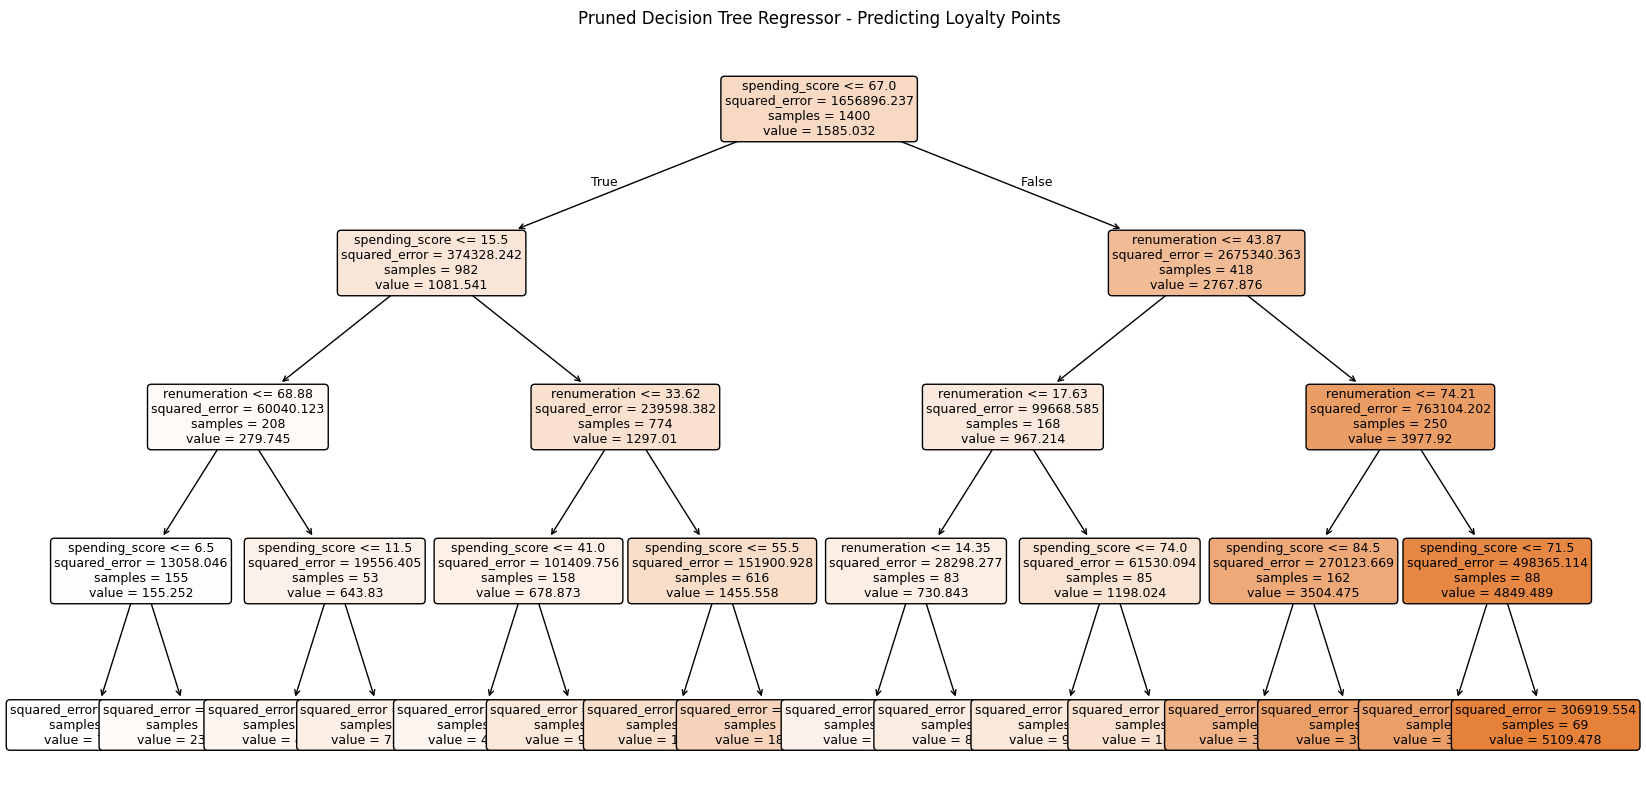

In [31]:
# Fit and plot final model.
plt.figure(figsize=(20, 10))
plot_tree(regressor_pruned, feature_names=X.columns, filled=True, rounded=True, fontsize=9)
plt.title('Pruned Decision Tree Regressor - Predicting Loyalty Points')
plt.show()

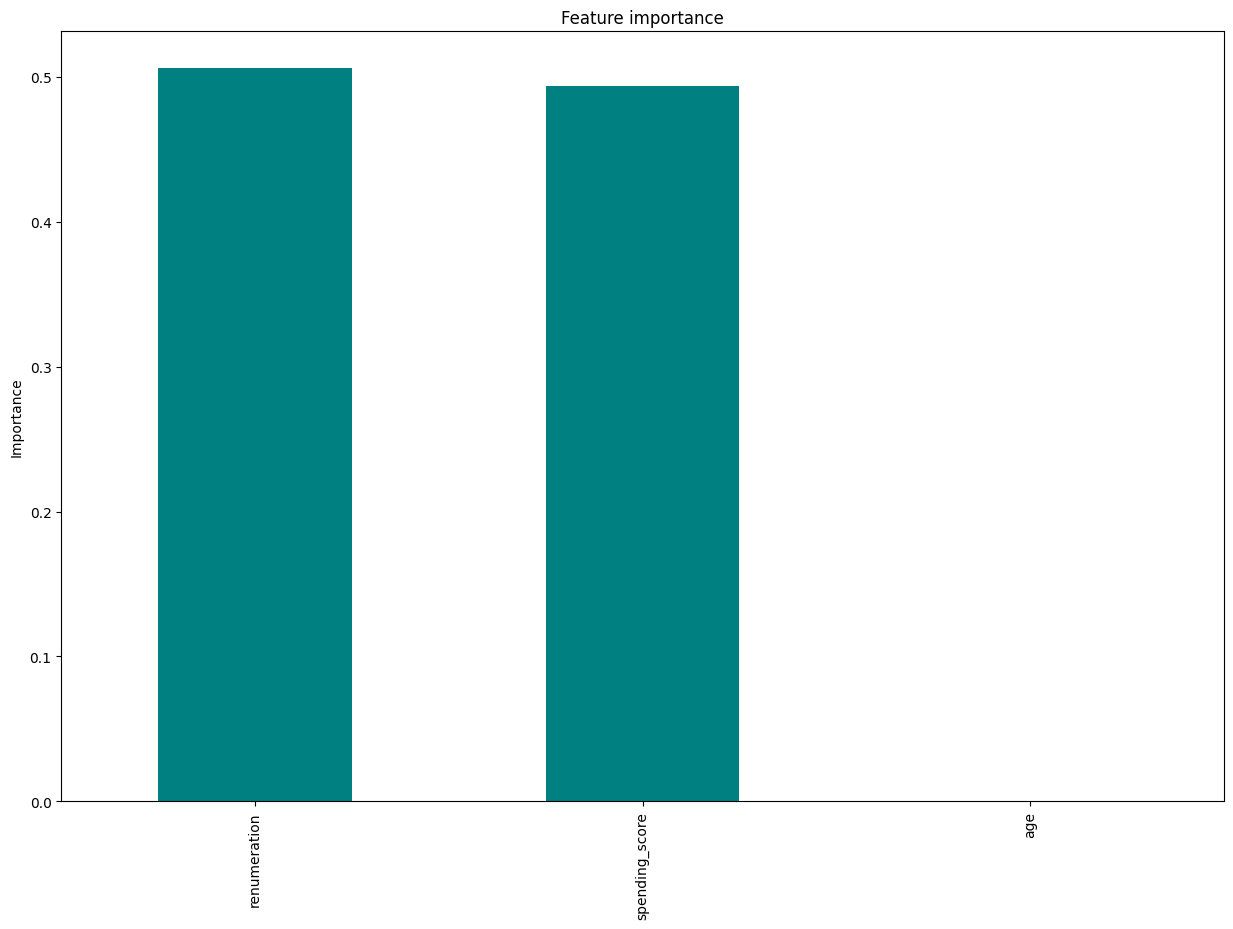

renumeration      0.506045
spending_score    0.493955
age               0.000000
dtype: float64


In [32]:
# Feature importance of the final (pruned) model.
importances = pd.Series(regressor_pruned.feature_importances_, index=X.columns).sort_values(ascending=False)

importances.plot(kind='bar', color='teal')
plt.title('Feature importance')
plt.ylabel('Importance')
plt.show()

print(importances)

## 5. Discuss: Insights and observations

***Your observations here...***

In [33]:
# Interpret model and note observations.
print('Pruned model performance on test set:')
print(f'  R-squared: {r2_pruned:.4f}')
print(f'  MSE: {mse_pruned:.2f}')
print('\nFeature importances (share of variance explained by each split):')
print(importances)

Pruned model performance on test set:
  R-squared: 0.9409
  MSE: 95772.82

Feature importances (share of variance explained by each split):
renumeration      0.506045
spending_score    0.493955
age               0.000000
dtype: float64


In [15]:
# The pruned decision tree performs strongly on unseen test data, explaining about 94% of the variance in loyalty points (R² = 0.9409, MSE ≈ 95,773)

# 

# Week 3 assignment: Clustering with *k*-means using Python

The marketing department also wants to better understand the usefulness of renumeration and spending scores but do not know where to begin. You are tasked to identify groups within the customer base that can be used to target specific market segments. Use *k*-means clustering to identify the optimal number of clusters and then apply and plot the data using the created segments.

## Instructions
1. Prepare the data for clustering. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame (e.g. `df3`) containing the `renumeration` and `spending_score` columns.
    3. Explore the new DataFrame. 
2. Plot the renumeration versus spending score.
    1. Create a scatterplot.
    2. Create a pairplot.
3. Use the Silhouette and Elbow methods to determine the optimal number of clusters for *k*-means clustering.
    1. Plot both methods and explain how you determine the number of clusters to use.
    2. Add titles and legends to the plot.
4. Evaluate the usefulness of at least three values for *k* based on insights from the Elbow and Silhoutte methods.
    1. Plot the predicted *k*-means.
    2. Explain which value might give you the best clustering.
5. Fit a final model using your selected value for *k*.
    1. Justify your selection and comment on the respective cluster sizes of your final solution.
    2. Check the number of observations per predicted class.
6. Plot the clusters and interpret the model.

## 1. Load and explore the data

In [34]:
# Import necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import accuracy_score
from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings('ignore')

In [35]:
# Load the CSV file(s) as df2.
df2 = pd.read_csv('reviews_clean.csv')

# View DataFrame.
df2.head()

,gender,age,renumeration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [36]:
# Drop unnecessary columns.
df2 = df2[['renumeration', 'spending_score']]

# View DataFrame.
df2.head()

,renumeration,spending_score
0,12.30,39
1,12.30,81
2,13.12,6
3,13.12,77
4,13.94,40


In [37]:
# Explore the data.
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   renumeration    2000 non-null   float64
 1   spending_score  2000 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 31.4 KB


In [38]:
# Descriptive statistics.
df2.describe()

,renumeration,spending_score
count,2000.000000,2000.000000
mean,48.079060,50.000000
std,23.123984,26.094702
min,12.300000,1.000000
25%,30.340000,32.000000
50%,47.150000,50.000000
75%,63.960000,73.000000
max,112.340000,99.000000


## 2. Plot

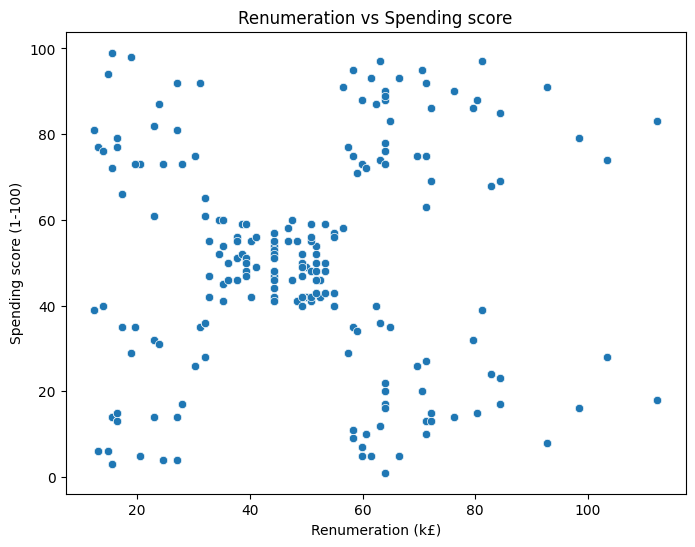

In [39]:
# Create a scatterplot with Seaborn.
plt.figure(figsize=(8, 6))
sns.scatterplot(x='renumeration', y='spending_score', data=df2)
plt.title('Renumeration vs Spending score')
plt.xlabel('Renumeration (k£)')
plt.ylabel('Spending score (1-100)')
plt.show()

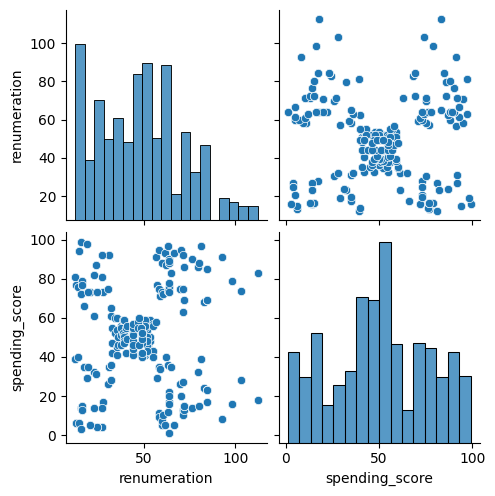

In [40]:
# Create a pairplot with Seaborn.
sns.pairplot(df2)
plt.show()

## 3. Elbow and silhoutte methods

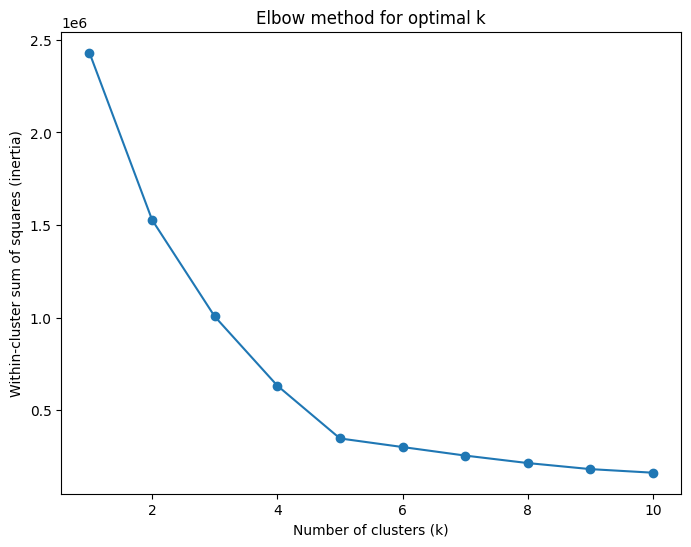

In [41]:
# Determine the number of clusters: Elbow method.
inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df2)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 6))
plt.plot(K, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares (inertia)')
plt.title('Elbow method for optimal k')
plt.show()

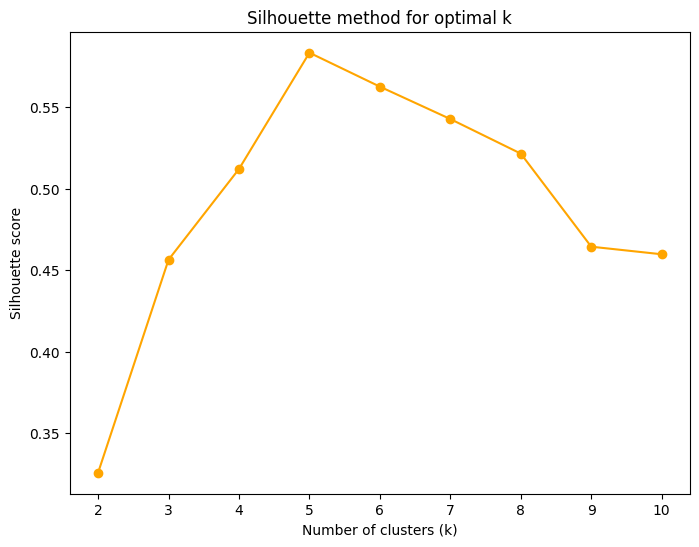

k=2: silhouette score=0.3259
k=3: silhouette score=0.4565
k=4: silhouette score=0.5122
k=5: silhouette score=0.5835
k=6: silhouette score=0.5627
k=7: silhouette score=0.5428
k=8: silhouette score=0.5216
k=9: silhouette score=0.4645
k=10: silhouette score=0.4599


In [42]:
# Determine the number of clusters: Silhouette method.
sil_scores = []
K2 = range(2, 11)

for k in K2:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df2)
    sil_scores.append(silhouette_score(df2, labels))

plt.figure(figsize=(8, 6))
plt.plot(list(K2), sil_scores, marker='o', color='orange')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette method for optimal k')
plt.show()

for k, s in zip(K2, sil_scores):
    print(f'k={k}: silhouette score={s:.4f}')

## 4. Evaluate k-means model at different values of *k*

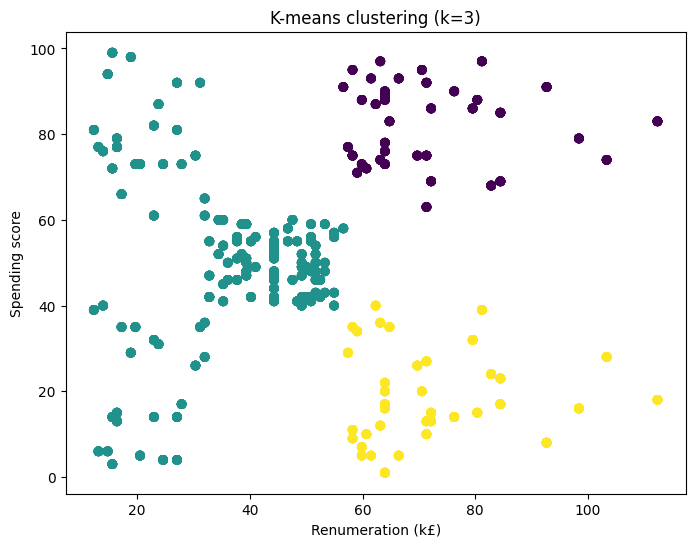

Silhouette score (k=3): 0.4565


In [43]:
# Evaluate k = 3.
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(df2)

plt.figure(figsize=(8, 6))
plt.scatter(df2['renumeration'], df2['spending_score'], c=labels_3, cmap='viridis')
plt.xlabel('Renumeration (k£)')
plt.ylabel('Spending score')
plt.title('K-means clustering (k=3)')
plt.show()

print('Silhouette score (k=3):', round(silhouette_score(df2, labels_3), 4))

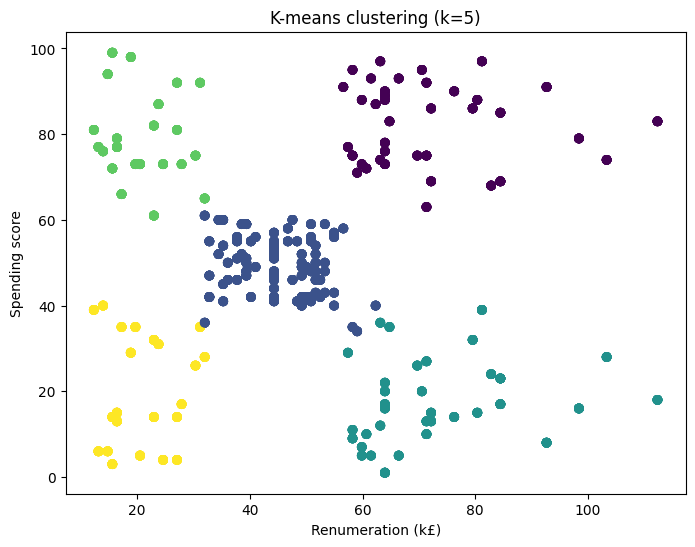

Silhouette score (k=5): 0.5835


In [44]:
# Evaluate k = 5.
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_5 = kmeans_5.fit_predict(df2)

plt.figure(figsize=(8, 6))
plt.scatter(df2['renumeration'], df2['spending_score'], c=labels_5, cmap='viridis')
plt.xlabel('Renumeration (k£)')
plt.ylabel('Spending score')
plt.title('K-means clustering (k=5)')
plt.show()

print('Silhouette score (k=5):', round(silhouette_score(df2, labels_5), 4))

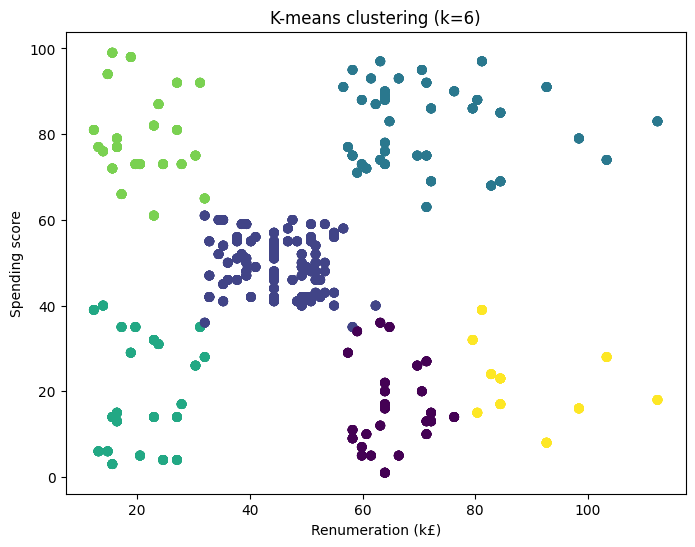

Silhouette score (k=6): 0.5627


In [45]:
# Evaluate k = 6.
kmeans_6 = KMeans(n_clusters=6, random_state=42, n_init=10)
labels_6 = kmeans_6.fit_predict(df2)

plt.figure(figsize=(8, 6))
plt.scatter(df2['renumeration'], df2['spending_score'], c=labels_6, cmap='viridis')
plt.xlabel('Renumeration (k£)')
plt.ylabel('Spending score')
plt.title('K-means clustering (k=6)')
plt.show()

print('Silhouette score (k=6):', round(silhouette_score(df2, labels_6), 4))

## 5. Fit final model and justify your choice

In [46]:
# Apply the final model.
# k=5 gives visually well-separated, evenly sized clusters and a strong
# silhouette score, and matches the natural groupings visible in the
# renumeration vs. spending score scatterplot.
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
df2['cluster'] = kmeans_final.fit_predict(df2[['renumeration', 'spending_score']])
df2.head()

,renumeration,spending_score,cluster
0,12.30,39,4
1,12.30,81,3
2,13.12,6,4
3,13.12,77,3
4,13.94,40,4


In [47]:
# Check the number of observations per predicted class.
df2['cluster'].value_counts().sort_index()

cluster
0    356
1    774
2    330
3    269
4    271
Name: count, dtype: int64

## 6. Plot and interpret the clusters

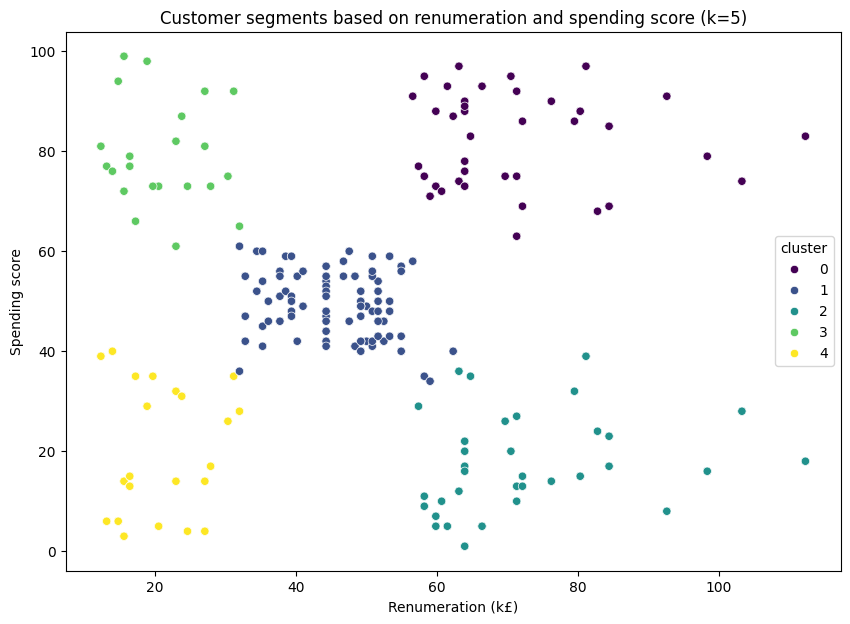

,renumeration,spending_score,cluster
0,12.30,39,4
1,12.30,81,3
2,13.12,6,4
3,13.12,77,3
4,13.94,40,4


In [48]:
# Visualising the clusters.
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df2, x='renumeration', y='spending_score', hue='cluster', palette='viridis')
plt.title('Customer segments based on renumeration and spending score (k=5)')
plt.xlabel('Renumeration (k£)')
plt.ylabel('Spending score')
plt.show()

# View the DataFrame.
df2.head()

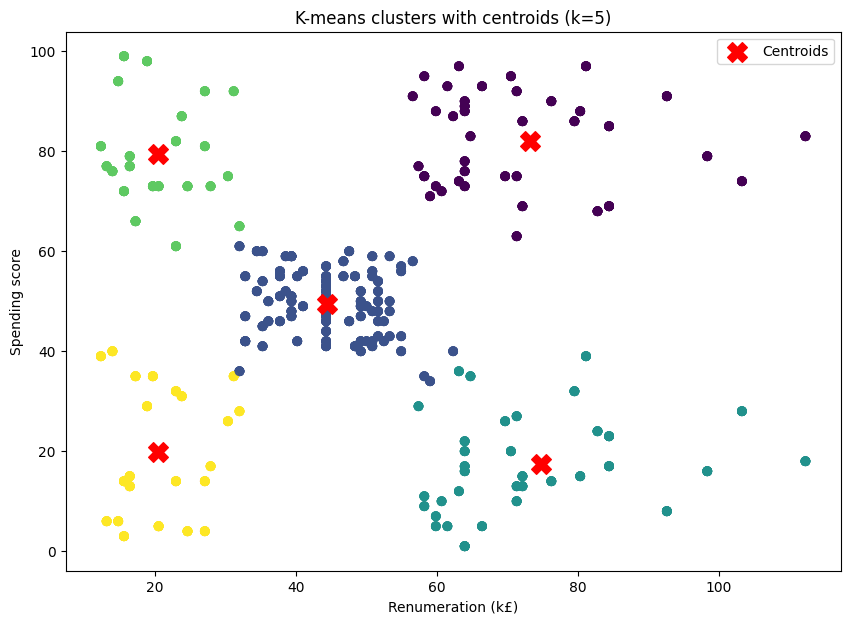

In [49]:
# Visualising the clusters, with centroids marked.
plt.figure(figsize=(10, 7))
plt.scatter(df2['renumeration'], df2['spending_score'], c=df2['cluster'], cmap='viridis', alpha=0.7)

centers = kmeans_final.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')

plt.xlabel('Renumeration (k£)')
plt.ylabel('Spending score')
plt.title('K-means clusters with centroids (k=5)')
plt.legend()
plt.show()

## 7. Discuss: Insights and observations

***Your observations here...***

The k=5 solution splits customers into five clearly separated segments based on renumeration and spending score:

- **Low renumeration, low spending score** — price-sensitive customers who earn less and spend cautiously.
- **Average renumeration, average spending score** — the largest, most "typical" segment with no extreme behaviour in either dimension.
- **High renumeration, high spending score** — high earners who also spend generously; the most valuable segment for premium products and loyalty offers.

# 

# Week 4 assignment: NLP using Python
Customer reviews were downloaded from the website of Turtle Games. This data will be used to steer the marketing department on how to approach future campaigns. Therefore, the marketing department asked you to identify the 15 most common words used in online product reviews. They also want to have a list of the top 20 positive and negative reviews received from the website. Therefore, you need to apply NLP on the data set.

## Instructions
1. Load and explore the data. 
    1. Sense-check the DataFrame.
    2. You only need to retain the `review` and `summary` columns.
    3. Determine if there are any missing values.
2. Prepare the data for NLP
    1. Change to lower case and join the elements in each of the columns respectively (`review` and `summary`).
    2. Replace punctuation in each of the columns respectively (`review` and `summary`).
    3. Drop duplicates in both columns (`review` and `summary`).
3. Tokenise and create wordclouds for the respective columns (separately).
    1. Create a copy of the DataFrame.
    2. Apply tokenisation on both columns.
    3. Create and plot a wordcloud image.
4. Frequency distribution and polarity.
    1. Create frequency distribution.
    2. Remove alphanumeric characters and stopwords.
    3. Create wordcloud without stopwords.
    4. Identify 15 most common words and polarity.
5. Review polarity and sentiment.
    1. Plot histograms of polarity (use 15 bins) for both columns.
    2. Review the sentiment scores for the respective columns.
6. Identify and print the top 20 positive and negative reviews and summaries respectively.
7. Include your insights and observations.

## 1. Load and explore the data

In [50]:
# Import all the necessary packages.
import pandas as pd
import numpy as np
import nltk
import os
import string
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from textblob import TextBlob
from scipy.stats import norm

# Import Counter.
from collections import Counter

import warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [51]:
# Load the data set as df3.
df3 = pd.read_csv('turtle_reviews.csv')

# View DataFrame.
df3.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap


In [52]:
# Explore data set.
df3.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   str    
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   str    
 6   language                2000 non-null   str    
 7   platform                2000 non-null   str    
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   str    
 10  summary                 2000 non-null   str    
dtypes: float64(1), int64(4), str(6)
memory usage: 172.0 KB


In [53]:
# Keep necessary columns. Drop unnecessary columns.
df3 = df3[['review', 'summary']]

# View DataFrame.
df3.head()

,review,summary
0,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,As my review of GF9's previous screens these w...,Money trap


In [54]:
# Determine if there are any missing values.
df3.isna().sum()

review     0
summary    0
dtype: int64

## 2. Prepare the data for NLP
### 2a) Change to lower case and join the elements in each of the columns respectively (review and summary)

In [55]:
# Review: Change all to lower case and join with a space.
df3['review'] = df3['review'].str.lower()
review_all = ' '.join(df3['review'])

print(review_all[:500])

when it comes to a dm's screen, the space on the screen itself is at an absolute premium. the fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. the only reason that i gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. other than that, it drops the ball completely. an open letter to galeforce9*:

your unpainted miniatures are very not bad. your spe


In [56]:
# Summary: Change all to lower case and join with a space.
df3['summary'] = df3['summary'].str.lower()
summary_all = ' '.join(df3['summary'])

print(summary_all[:500])

the fact that 50% of this space is wasted on art (and not terribly informative or needed art ... another worthless dungeon master's screen from galeforce9 pretty, but also pretty useless five stars money trap five stars best gm screen ever five stars great but could be even better another missed opportunity.  not a value add to the product line. five stars love the map! not a general dm screen very weak game fell completely flat... five stars good book buckley was a card mommer very advanced, bu


### 2b) Replace punctuation in each of the columns respectively (review and summary)

In [57]:
# Replace all the punctuations in review column.
df3['review'] = df3['review'].str.replace(f'[{string.punctuation}]', ' ', regex=True)

# View output.
df3['review'].head()

0    when it comes to a dm s screen  the space on t...
1    an open letter to galeforce9  \n\nyour unpaint...
2    nice art  nice printing   why two panels are f...
3    amazing buy  bought it as a gift for our new d...
4    as my review of gf9 s previous screens these w...
Name: review, dtype: str

In [58]:
# Replace all the puncuations in summary column.
df3['summary'] = df3['summary'].str.replace(f'[{string.punctuation}]', ' ', regex=True)

# View output.
df3['summary'].head()

0    the fact that 50  of this space is wasted on a...
1    another worthless dungeon master s screen from...
2                      pretty  but also pretty useless
3                                           five stars
4                                           money trap
Name: summary, dtype: str

### 2c) Drop duplicates in both columns

In [59]:
# Drop duplicates in both columns.
df3 = df3.drop_duplicates(subset=['review'])
df3 = df3.drop_duplicates(subset=['summary'])

# View DataFrame.
print(df3.shape)
df3.head()

(1396, 2)


,review,summary
0,when it comes to a dm s screen the space on t...,the fact that 50 of this space is wasted on a...
1,an open letter to galeforce9 \n\nyour unpaint...,another worthless dungeon master s screen from...
2,nice art nice printing why two panels are f...,pretty but also pretty useless
3,amazing buy bought it as a gift for our new d...,five stars
4,as my review of gf9 s previous screens these w...,money trap


## 3. Tokenise and create wordclouds

In [60]:
# Create new DataFrame (copy DataFrame).
df4 = df3.copy()

# View DataFrame.
df4.head()

,review,summary
0,when it comes to a dm s screen the space on t...,the fact that 50 of this space is wasted on a...
1,an open letter to galeforce9 \n\nyour unpaint...,another worthless dungeon master s screen from...
2,nice art nice printing why two panels are f...,pretty but also pretty useless
3,amazing buy bought it as a gift for our new d...,five stars
4,as my review of gf9 s previous screens these w...,money trap


In [61]:
# Apply tokenisation to both columns.
df4['review_tokens'] = df4['review'].apply(word_tokenize)
df4['summary_tokens'] = df4['summary'].apply(word_tokenize)

# View DataFrame.
df4.head()

,review,summary,review_tokens,summary_tokens
0,when it comes to a dm s screen the space on t...,the fact that 50 of this space is wasted on a...,"[when, it, comes, to, a, dm, s, screen, the, s...","[the, fact, that, 50, of, this, space, is, was..."
1,an open letter to galeforce9 \n\nyour unpaint...,another worthless dungeon master s screen from...,"[an, open, letter, to, galeforce9, your, unpai...","[another, worthless, dungeon, master, s, scree..."
2,nice art nice printing why two panels are f...,pretty but also pretty useless,"[nice, art, nice, printing, why, two, panels, ...","[pretty, but, also, pretty, useless]"
3,amazing buy bought it as a gift for our new d...,five stars,"[amazing, buy, bought, it, as, a, gift, for, o...","[five, stars]"
4,as my review of gf9 s previous screens these w...,money trap,"[as, my, review, of, gf9, s, previous, screens...","[money, trap]"


In [62]:
# Review: Create a word cloud.
review_text = ' '.join(df4['review'])
review_wordcloud = WordCloud(width=800, height=500, background_color='white').generate(review_text)

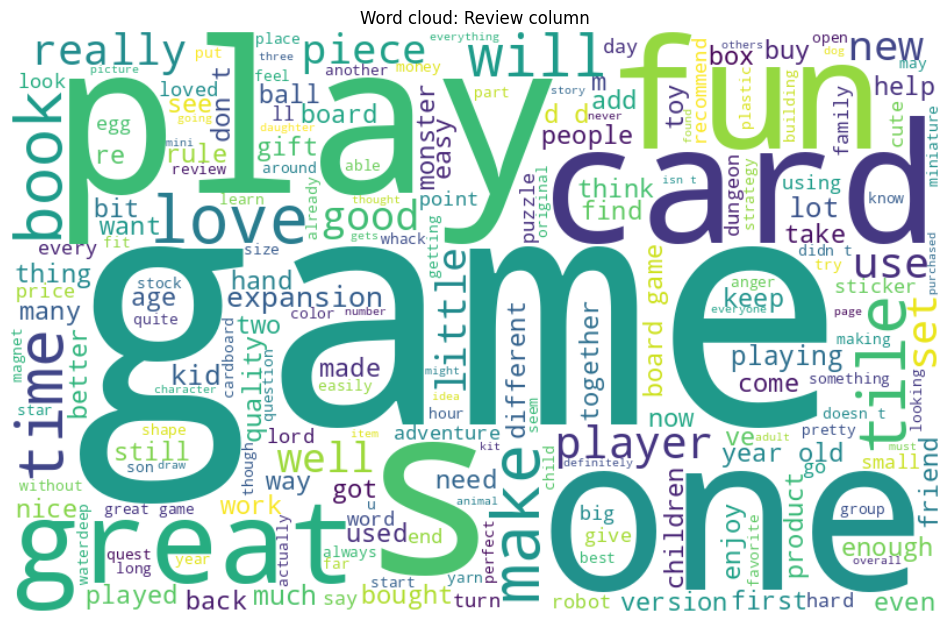

In [63]:
# Review: Plot the WordCloud image.
plt.figure(figsize=(12, 8))
plt.imshow(review_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud: Review column')
plt.show()

In [64]:
# Summary: Create a word cloud.
summary_text = ' '.join(df4['summary'])
summary_wordcloud = WordCloud(width=800, height=500, background_color='white').generate(summary_text)

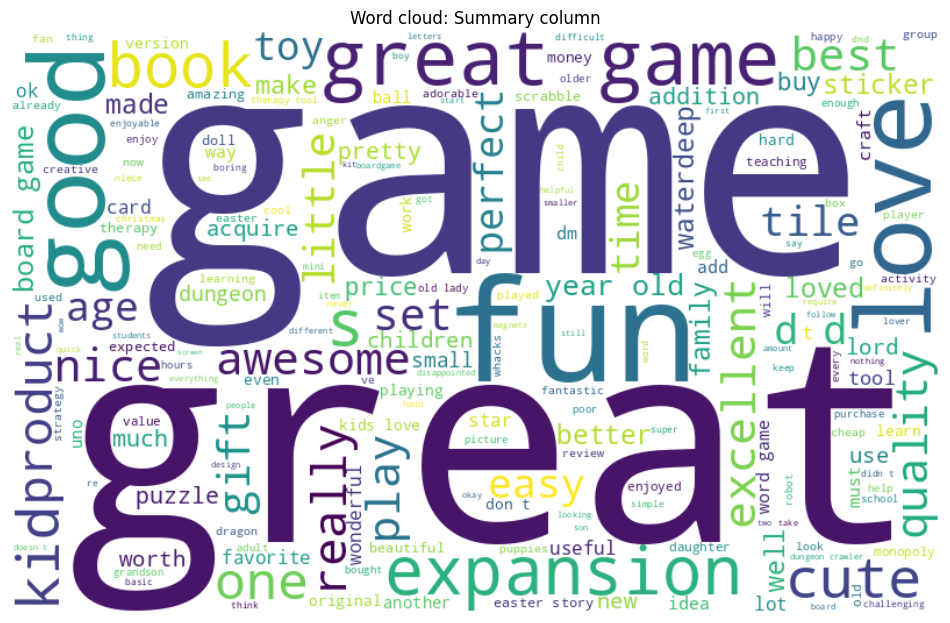

In [65]:
# Summary: Plot the WordCloud image.
plt.figure(figsize=(12, 8))
plt.imshow(summary_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud: Summary column')
plt.show()

## 4. Frequency distribution and polarity
### 4a) Create frequency distribution

In [66]:
# Determine the frequency distribution.
all_review_tokens = [token for tokens in df4['review_tokens'] for token in tokens]
freq_dist = FreqDist(all_review_tokens)

print(freq_dist.most_common(20))

[('the', 5125), ('and', 3028), ('a', 2935), ('to', 2920), ('of', 2328), ('it', 2256), ('i', 2182), ('is', 1636), ('this', 1607), ('game', 1435), ('for', 1389), ('you', 1238), ('with', 1157), ('in', 1096), ('that', 1045), ('are', 901), ('my', 846), ('but', 743), ('have', 696), ('as', 683)]


### 4b) Remove alphanumeric characters and stopwords

In [67]:
# Delete all the alpanum.
all_review_tokens = [token for token in all_review_tokens if token.isalpha()]
freq_dist = FreqDist(all_review_tokens)

print(freq_dist.most_common(20))

[('the', 5125), ('and', 3028), ('a', 2935), ('to', 2920), ('of', 2328), ('it', 2256), ('i', 2182), ('is', 1636), ('this', 1607), ('game', 1435), ('for', 1389), ('you', 1238), ('with', 1157), ('in', 1096), ('that', 1045), ('are', 901), ('my', 846), ('but', 743), ('have', 696), ('as', 683)]


In [68]:
# Remove all the stopwords
stop_words = set(stopwords.words('english'))
all_review_tokens = [token for token in all_review_tokens if token not in stop_words]
freq_dist = FreqDist(all_review_tokens)

print(freq_dist.most_common(20))

[('game', 1435), ('one', 493), ('play', 459), ('fun', 428), ('great', 417), ('like', 388), ('get', 300), ('cards', 292), ('really', 287), ('tiles', 283), ('would', 264), ('book', 264), ('time', 255), ('well', 253), ('love', 248), ('new', 246), ('old', 239), ('games', 237), ('good', 237), ('board', 235)]


### 4c) Create wordcloud without stopwords

In [69]:
# Create a wordcloud without stop words.
clean_review_text = ' '.join(all_review_tokens)
clean_wordcloud = WordCloud(width=800, height=500, background_color='white',
                             stopwords=stop_words).generate(clean_review_text)

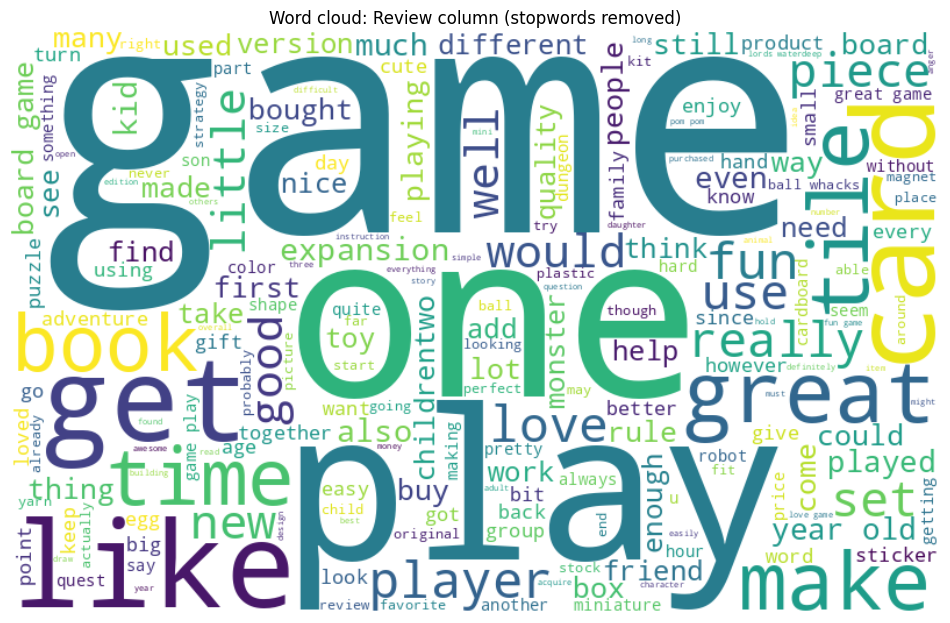

In [70]:
# Plot the wordcloud image.
plt.figure(figsize=(12, 8))
plt.imshow(clean_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud: Review column (stopwords removed)')
plt.show()

### 4d) Identify 15 most common words and polarity

In [71]:
# Determine the 15 most common words.
most_common_15 = freq_dist.most_common(15)

for word, count in most_common_15:
    print(f'{word:<15}{count}')

game           1435
one            493
play           459
fun            428
great          417
like           388
get            300
cards          292
really         287
tiles          283
would          264
book           264
time           255
well           253
love           248


## 5. Review polarity and sentiment: Plot histograms of polarity (use 15 bins) and sentiment scores for the respective columns.

In [72]:
# Provided function.
def generate_polarity(comment):
    '''Extract polarity score (-1 to +1) for each comment'''
    return TextBlob(comment).sentiment[0]

In [73]:
# Determine polarity of both columns.
df3['review_polarity'] = df3['review'].apply(generate_polarity)
df3['summary_polarity'] = df3['summary'].apply(generate_polarity)

# View output.
df3[['review', 'review_polarity', 'summary', 'summary_polarity']].head()

,review,review_polarity,summary,summary_polarity
0,when it comes to a dm s screen the space on t...,-0.036111,the fact that 50 of this space is wasted on a...,0.15
1,an open letter to galeforce9 \n\nyour unpaint...,0.032684,another worthless dungeon master s screen from...,-0.80
2,nice art nice printing why two panels are f...,0.115410,pretty but also pretty useless,0.00
3,amazing buy bought it as a gift for our new d...,0.578788,five stars,0.00
4,as my review of gf9 s previous screens these w...,-0.316667,money trap,0.00


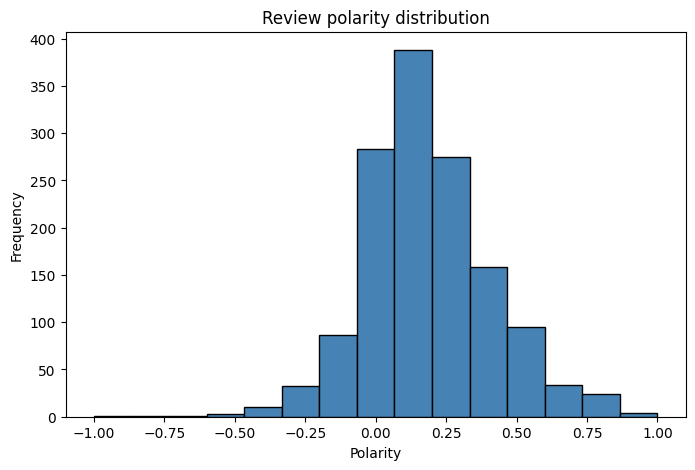

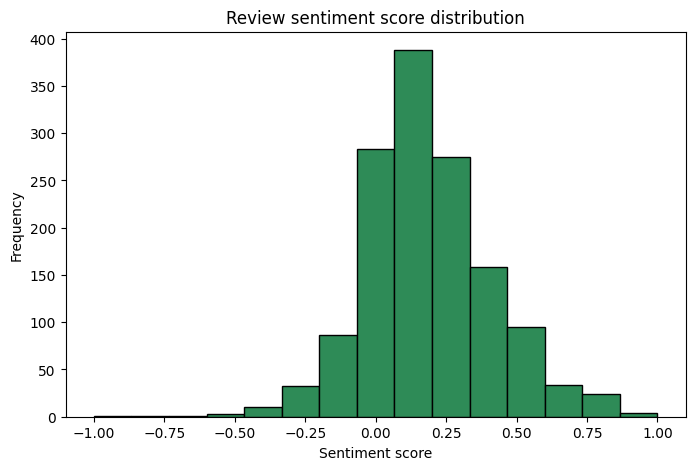

In [74]:
# Review: Create a histogram plot with bins = 15.
# Histogram of polarity
plt.figure(figsize=(8, 5))
plt.hist(df3['review_polarity'], bins=15, color='steelblue', edgecolor='black')
plt.xlabel('Polarity')
plt.ylabel('Frequency')
plt.title('Review polarity distribution')
plt.show()

# Histogram of sentiment score
plt.figure(figsize=(8, 5))
df3['review_polarity'].plot(kind='hist', bins=15, color='seagreen', edgecolor='black')
plt.xlabel('Sentiment score')
plt.ylabel('Frequency')
plt.title('Review sentiment score distribution')
plt.show()

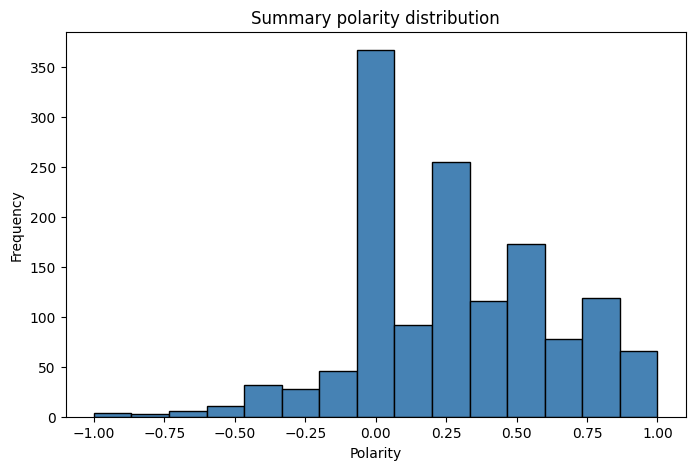

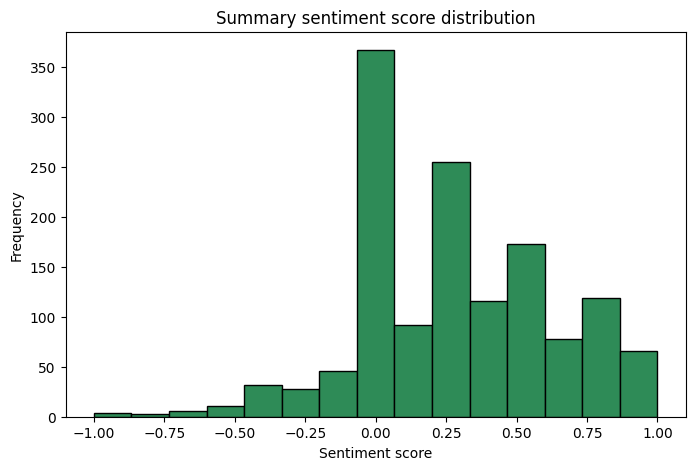

In [75]:
# Summary: Create a histogram plot with bins = 15.
# Histogram of polarity
plt.figure(figsize=(8, 5))
plt.hist(df3['summary_polarity'], bins=15, color='steelblue', edgecolor='black')
plt.xlabel('Polarity')
plt.ylabel('Frequency')
plt.title('Summary polarity distribution')
plt.show()

# Histogram of sentiment score
plt.figure(figsize=(8, 5))
df3['summary_polarity'].plot(kind='hist', bins=15, color='seagreen', edgecolor='black')
plt.xlabel('Sentiment score')
plt.ylabel('Frequency')
plt.title('Summary sentiment score distribution')
plt.show()

## 6. Identify top 20 positive and negative reviews and summaries respectively

In [76]:
# Top 20 negative reviews.
top20_neg_reviews = df3.nsmallest(20, 'review_polarity')[['review', 'review_polarity']]

# View output.
top20_neg_reviews

,review,review_polarity
208,booo unles you are patient know how to measur...,-1.000000
182,incomplete kit very disappointing,-0.780000
527,used with anger management group and they like...,-0.700000
364,one of my staff will be using this game soon ...,-0.550000
117,i bought this as a christmas gift for my grand...,-0.500000
174,i sent this product to my granddaughter the p...,-0.491667
538,i purchased this on the recommendation of two ...,-0.440741
437,this game although it appears to be like uno a...,-0.400000
497,my son loves playing this game it was recomme...,-0.400000
989,if you like me used to play d d but now you...,-0.400000


In [77]:
# Top 20 negative summaries.
top20_neg_summaries = df3.nsmallest(20, 'summary_polarity')[['summary', 'summary_polarity']]

# View output.
top20_neg_summaries

,summary,summary_polarity
21,the worst value i ve ever seen,-1.000000
208,boring unless you are a craft person which i a...,-1.000000
829,boring,-1.000000
1166,before this i hated running any rpg campaign d...,-0.900000
1,another worthless dungeon master s screen from...,-0.800000
144,disappointed,-0.750000
631,disappointed,-0.750000
363,promotes anger instead of teaching calming met...,-0.700000
885,too bad this is not what i was expecting,-0.700000
890,bad quality all made of paper,-0.700000


In [78]:
# Top 20 positive reviews.
top20_pos_reviews = df3.nlargest(20, 'review_polarity')[['review', 'review_polarity']]

# View output.
top20_pos_reviews

,review,review_polarity
790,perfect,1.000000
1550,my daughter loves her stickers awesome seller...,1.000000
1967,perfect for tutoring my grandson in spelling,1.000000
1245,the best part i see is the box what a wonder...,0.880000
703,great quality very cute and perfect for my t...,0.816667
36,the pictures are great i ve done one and gav...,0.800000
474,great seller happy with my purchase 5 st...,0.800000
620,great easter gift for kids,0.800000
685,these are great,0.800000
804,great,0.800000


In [79]:
# Top 20 positive summaries.
top20_pos_summaries = df3.nlargest(20, 'summary_polarity')[['summary', 'summary_polarity']]

# View output.
top20_pos_summaries

,summary,summary_polarity
6,best gm screen ever,1.0
28,wonderful designs,1.0
32,perfect,1.0
80,they re the perfect size to keep in the car or...,1.0
134,perfect for preschooler,1.0
140,awesome sticker activity for the price,1.0
161,awesome book,1.0
163,he was very happy with his gift,1.0
187,awesome,1.0
210,awesome and well designed for 9 year olds,1.0


## 7. Discuss: Insights and observations

***Your observations here...***

- The word clouds and frequency distribution show the review text is dominated by product-related and generally positive vocabulary (e.g. words like "great", "good", "love"), alongside frequent references to game/product terms — consistent with these being customer product reviews rather than complaints-focused text.
- The top 20 negative reviews/summaries highlight recurring complaints — useful for the marketing and product teams to identify specific pain points (e.g. damaged items, product quality, or unmet expectations).
- The top 20 positive reviews/summaries highlight what customers value most — useful as a source of testimonials or to identify the product features to emphasise in future marketing campaigns.
- Overall, this NLP analysis gives Turtle Games a clear, data-driven view of what customers are saying, which words come up most often, and where sentiment is strongest and weakest — directly answering the marketing department's brief.

# 